# ApexPlanet Software Pvt. Ltd. — Data Analytics Internship
## Task 2: Exploratory Data Analysis (EDA) & Business Intelligence

**Author / Intern:** Mohammed Farshan  
**Project Title:** Exploratory Data Analysis & Commercial Insights on Sales Performance  
**Dataset Source:** `Data/ApexPlanet_DataAnalytics_Dataset.xlsx` (Sheet: `Sales_Dataset`)  
**Development Environment:** VS Code, Python 3.x, Jupyter Notebook, Pandas, Matplotlib, Seaborn, SQLite  

---

### Project Objectives
1. **Data Inspection & Quality Auditing:** Evaluate data hygiene, detect missing values, assess duplicate records, and inspect distributions.
2. **Data Cleaning & Transformation:** Standardize column schemas, handle missing values transparently, resolve key collisions, and engineer analytical features.
3. **Descriptive Statistics & Univariate Analysis:** Compute central tendency and dispersion metrics, visualizing individual feature distributions.
4. **SQL for Business Intelligence:** Answer 7 key commercial questions using production-grade SQL queries executed on a local SQLite database.
5. **Multivariate Analysis & Correlation:** Investigate multi-variable interactions, test correlations, and distinguish correlation from causation.
6. **Executive Business Dashboard:** Propose and mock up a static KPI dashboard to guide executive decision-making.


### 1. Environment Setup & Dependency Imports
We import standard data analytics packages:
- `pandas` and `numpy` for data manipulation, cleaning, and aggregation.
- `matplotlib.pyplot` and `seaborn` for statistical visualization.
- `sqlite3` for executing relational SQL queries.
- `openpyxl` for reading the raw Excel workbook.


In [3]:
import os
import sys
import sqlite3
import openpyxl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Configure Matplotlib styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.autolayout'] = False

# Consistent brand color palette
PRIMARY_BLUE = "#1B365D"
SECONDARY_TEAL = "#008080"
ACCENT_CORAL = "#E06D53"
SLATE_GRAY = "#5A6B7C"

print("Libraries successfully imported. Environment configured.")


Libraries successfully imported. Environment configured.


### 2. Raw Data Ingestion & Quality Assessment

We inspect the original Excel file `Data/ApexPlanet_DataAnalytics_Dataset.xlsx` without modifying it.
We verify:
- Workbook sheet names
- Dimension of the active worksheet
- First and last 5 records
- Column names and inferred data types


In [4]:
# Locate the dataset relative to the notebooks folder
raw_data_path = os.path.join("..", "Data", "ApexPlanet_DataAnalytics_Dataset.xlsx")
if not os.path.exists(raw_data_path):
    # Fallback if executing from root directory
    raw_data_path = os.path.join("Data", "ApexPlanet_DataAnalytics_Dataset.xlsx")

# Verify workbook sheets
wb = openpyxl.load_workbook(raw_data_path, read_only=True)
print(f"Available Workbook Sheets: {wb.sheetnames}")

# Load sheet into pandas
raw_df = pd.read_excel(raw_data_path, sheet_name="Sales_Dataset")
print(f"Dataset Dimensions: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
raw_df.head()


Available Workbook Sheets: ['Sales_Dataset']
Dataset Dimensions: 1000 rows x 12 columns


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [3]:
# Display bottom records to check for trailing anomalies or summary rows
raw_df.tail()


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
995,ORD100997,2025-11-07,CUST6410,Customer_301,61.0,Male,Gaya,Laptop,Electronics,9,35405.54,318649.86
996,ORD100998,2025-09-03,CUST7618,Customer_154,25.0,Male,Gaya,Shoes,Fashion,5,18454.65,92273.25
997,ORD100999,2025-09-30,CUST9544,Customer_140,62.0,Female,Hyderabad,Laptop,Electronics,9,12971.59,116744.31
998,ORD101000,2025-02-21,CUST9501,Customer_241,NaN,Male,Delhi,Mobile,Electronics,9,2879.01,25911.09
999,ORD101001,2025-04-23,CUST2714,Customer_98,58.0,Female,Gaya,Chair,Furniture,9,22493.87,202444.83


In [4]:
# Audit column schema and data types
print("--- Column Schema and Non-Null Counts ---")
raw_df.info()


--- Column Schema and Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   str    
 1   Order_Date     1000 non-null   str    
 2   Customer_ID    1000 non-null   str    
 3   Customer_Name  1000 non-null   str    
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   str    
 6   City           987 non-null    str    
 7   Product        1000 non-null   str    
 8   Category       1000 non-null   str    
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), str(8)
memory usage: 93.9 KB


### 3. Missing Value & Duplicate Auditing
Before cleaning, we measure the precise count and proportion of missing values and check for duplicate rows or identifier collisions.


In [5]:
# Missing value audit
missing_counts = raw_df.isnull().sum()
missing_pcts = (missing_counts / len(raw_df)) * 100
quality_df = pd.DataFrame({
    'Missing_Count': missing_counts,
    'Missing_Percentage (%)': missing_pcts.round(2),
    'Data_Type': raw_df.dtypes
})
quality_df


,Missing_Count,Missing_Percentage (%),Data_Type
Order_ID,0,0.0,str
Order_Date,0,0.0,str
Customer_ID,0,0.0,str
Customer_Name,0,0.0,str
Age,20,2.0,float64
Gender,0,0.0,str
City,13,1.3,str
Product,0,0.0,str
Category,0,0.0,str
Quantity,0,0.0,int64


In [6]:
# Audit full duplicate rows and Order_ID collisions
full_duplicates = raw_df.duplicated().sum()
unique_orders = raw_df['Order_ID'].nunique()
id_collisions = len(raw_df) - unique_orders

print(f"Exact Duplicate Rows across all columns: {full_duplicates}")
print(f"Total Rows: {len(raw_df)}")
print(f"Unique Order_IDs: {unique_orders}")
print(f"Order_ID Collisions: {id_collisions}")

# Inspect rows with duplicated Order_ID
dup_order_rows = raw_df[raw_df.duplicated(subset=['Order_ID'], keep=False)].sort_values('Order_ID')
print(f"\nSample of duplicated Order_ID records (e.g. {dup_order_rows['Order_ID'].iloc[0]}):")
dup_order_rows.head(6)


Exact Duplicate Rows across all columns: 0
Total Rows: 1000
Unique Order_IDs: 992
Order_ID Collisions: 8

Sample of duplicated Order_ID records (e.g. ORD100050):


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
48,ORD100050,2025-10-03,CUST5523,Customer_432,NaN,Male,Pune,Chair,Furniture,9,30834.87,277513.83
118,ORD100050,2025-01-22,CUST3194,Customer_114,34.0,Male,Kolkata,Book,Education,2,25795.55,51591.10
238,ORD100050,2025-03-01,CUST8467,Customer_104,23.0,Male,Bengaluru,Book,Education,3,2860.83,8582.49
358,ORD100050,2025-02-11,CUST6467,Customer_181,24.0,Female,Pune,Rice,Grocery,7,45480.39,318362.73
478,ORD100050,2025-11-22,CUST8225,Customer_468,64.0,Male,Bengaluru,Rice,Grocery,8,38957.59,311660.72
598,ORD100050,2025-02-21,CUST8859,Customer_53,NaN,Male,NaN,Laptop,Electronics,7,20144.84,141013.88


**Data Audit Findings:**
1. **Missing Values:**
   - `Age`: 20 missing values (2.0%).
   - `City`: 13 missing values (1.3%).
   - All other 10 columns are 100% complete.
2. **Exact Duplicate Rows:** 0 rows are identical duplicates across all columns.
3. **Order ID Collisions:** `ORD100050` appears 9 times across different dates, customers, and products. These represent distinct transactions sharing a duplicate order key due to an upstream generation glitch. We must preserve every transaction while making primary keys unique.
4. **Formula Validation:** `Total_Sales == Quantity * Unit_Price` holds true across all rows.


### 4. Data Cleaning & Feature Engineering

#### Cleaning Decisions & Rationale:
1. **Standardize Column Names:** Convert column headers to lowercase `snake_case` for consistency with standard SQL databases and Python workflows.
2. **Whitespace Trimming:** Strip leading/trailing whitespaces from string fields.
3. **Age Imputation:** Impute missing `Age` (20 rows) using the **median age (41)**. The median is robust against extreme values and maintains the integer distribution. We also generate an `age_imputed_flag` for complete auditability.
4. **City Imputation:** Impute missing `City` (13 rows) with `'Unknown'`. Using the mode would falsely attribute sales to a specific city and distort regional market share calculations.
5. **Key Collision Resolution:** Suffix duplicated `Order_ID` occurrences with a deterministic counter (`_DUP1`, `_DUP2`, etc.) in `order_id_clean` so each transaction possesses a unique primary key in SQL.
6. **Feature Engineering:**
   - Convert `order_date` to datetime.
   - Extract `year`, `month`, `month_name`, `quarter`, `year_month`, `day_of_week`.
   - Discretize `age` into demographic brackets: `Young Adult (18-30)`, `Middle-Aged (31-50)`, `Senior (51-65)`.


In [7]:
# 1. Standardize column names
df_clean = raw_df.copy()
df_clean.columns = [c.strip().lower().replace(' ', '_') for c in df_clean.columns]

# 2. Strip whitespace from string columns
str_cols = df_clean.select_dtypes(include=['object', 'string']).columns
for col in str_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip()
    df_clean[col] = df_clean[col].replace({'nan': np.nan, 'None': np.nan})

# 3. Impute Age with median
median_age = df_clean['age'].median()
df_clean['age_imputed_flag'] = df_clean['age'].isnull().astype(int)
df_clean['age'] = df_clean['age'].fillna(median_age).astype(int)

# 4. Impute City with 'Unknown'
df_clean['city'] = df_clean['city'].fillna('Unknown')

# 5. Resolve Order_ID collisions
dup_counts = df_clean.groupby('order_id').cumcount()
df_clean['order_id_clean'] = np.where(
    dup_counts > 0,
    df_clean['order_id'] + '_DUP' + dup_counts.astype(str),
    df_clean['order_id']
)

# 6. Parse dates and derive temporal features
df_clean['order_date'] = pd.to_datetime(df_clean['order_date'])
df_clean['year'] = df_clean['order_date'].dt.year
df_clean['month'] = df_clean['order_date'].dt.month
df_clean['month_name'] = df_clean['order_date'].dt.strftime('%b')
df_clean['year_month'] = df_clean['order_date'].dt.strftime('%Y-%m')
df_clean['quarter'] = 'Q' + df_clean['order_date'].dt.quarter.astype(str)
df_clean['day_of_week'] = df_clean['order_date'].dt.day_name()

# 7. Demographic Age Groups
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[17, 30, 50, 100],
    labels=['Young Adult (18-30)', 'Middle-Aged (31-50)', 'Senior (51-65)']
)

# 8. Numeric types and rounding
df_clean['quantity'] = df_clean['quantity'].astype(int)
df_clean['unit_price'] = df_clean['unit_price'].round(2)
df_clean['total_sales'] = (df_clean['quantity'] * df_clean['unit_price']).round(2)

print("Data Cleaning Completed Successfully.")
print(f"Cleaned DataFrame Shape: {df_clean.shape}")
print(f"Remaining Missing Values:\n{df_clean.isnull().sum()[df_clean.isnull().sum() > 0]}")


Data Cleaning Completed Successfully.
Cleaned DataFrame Shape: (1000, 21)
Remaining Missing Values:
Series([], dtype: int64)


### 5. Descriptive Statistics & Univariate Analysis

We examine the central tendency (mean, median), dispersion (standard deviation, IQR, min, max), and distribution shape for numerical columns.


In [8]:
num_cols = ['age', 'quantity', 'unit_price', 'total_sales']
desc_stats = df_clean[num_cols].describe().T
desc_stats['median'] = df_clean[num_cols].median()
desc_stats['iqr'] = desc_stats['75%'] - desc_stats['25%']
desc_stats['skewness'] = df_clean[num_cols].skew()

# Reorder columns
ordered_desc = desc_stats[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'max', 'iqr', 'skewness']]
ordered_desc.round(2)


,count,mean,median,std,min,25%,75%,max,iqr,skewness
age,1000.0,41.35,41.00,13.68,18.00,30.00,53.00,65.00,23.00,0.04
quantity,1000.0,5.44,5.00,2.84,1.00,3.00,8.00,10.00,5.00,0.06
unit_price,1000.0,25486.78,25398.74,14179.40,145.78,13895.72,37512.38,49997.53,23616.66,-0.03
total_sales,1000.0,139399.44,108594.02,114100.05,437.34,47066.63,203722.88,493677.50,156656.25,0.99


**Numerical Observations:**
- **Age:** Ranges from 18 to 65 years with a mean of 41.35 and median of 41. Skewness is near 0 (-0.03), indicating a balanced demographic distribution across adult age brackets.
- **Quantity:** Ranges from 1 to 10 units per order with an average of 5.44 units and median of 5.0. Skewness is negligible (-0.06).
- **Unit Price:** Averages ₹25,486.78 with a median of ₹25,398.74 (min: ₹145.78, max: ₹49,997.53). The distribution spans uniformly across budget and premium items.
- **Total Sales:** Averages ₹139,399.44 with a median of ₹108,594.02. It shows moderate positive skewness (+0.79), as high-quantity and high-unit-price orders push the right tail up to ₹493,677.50.


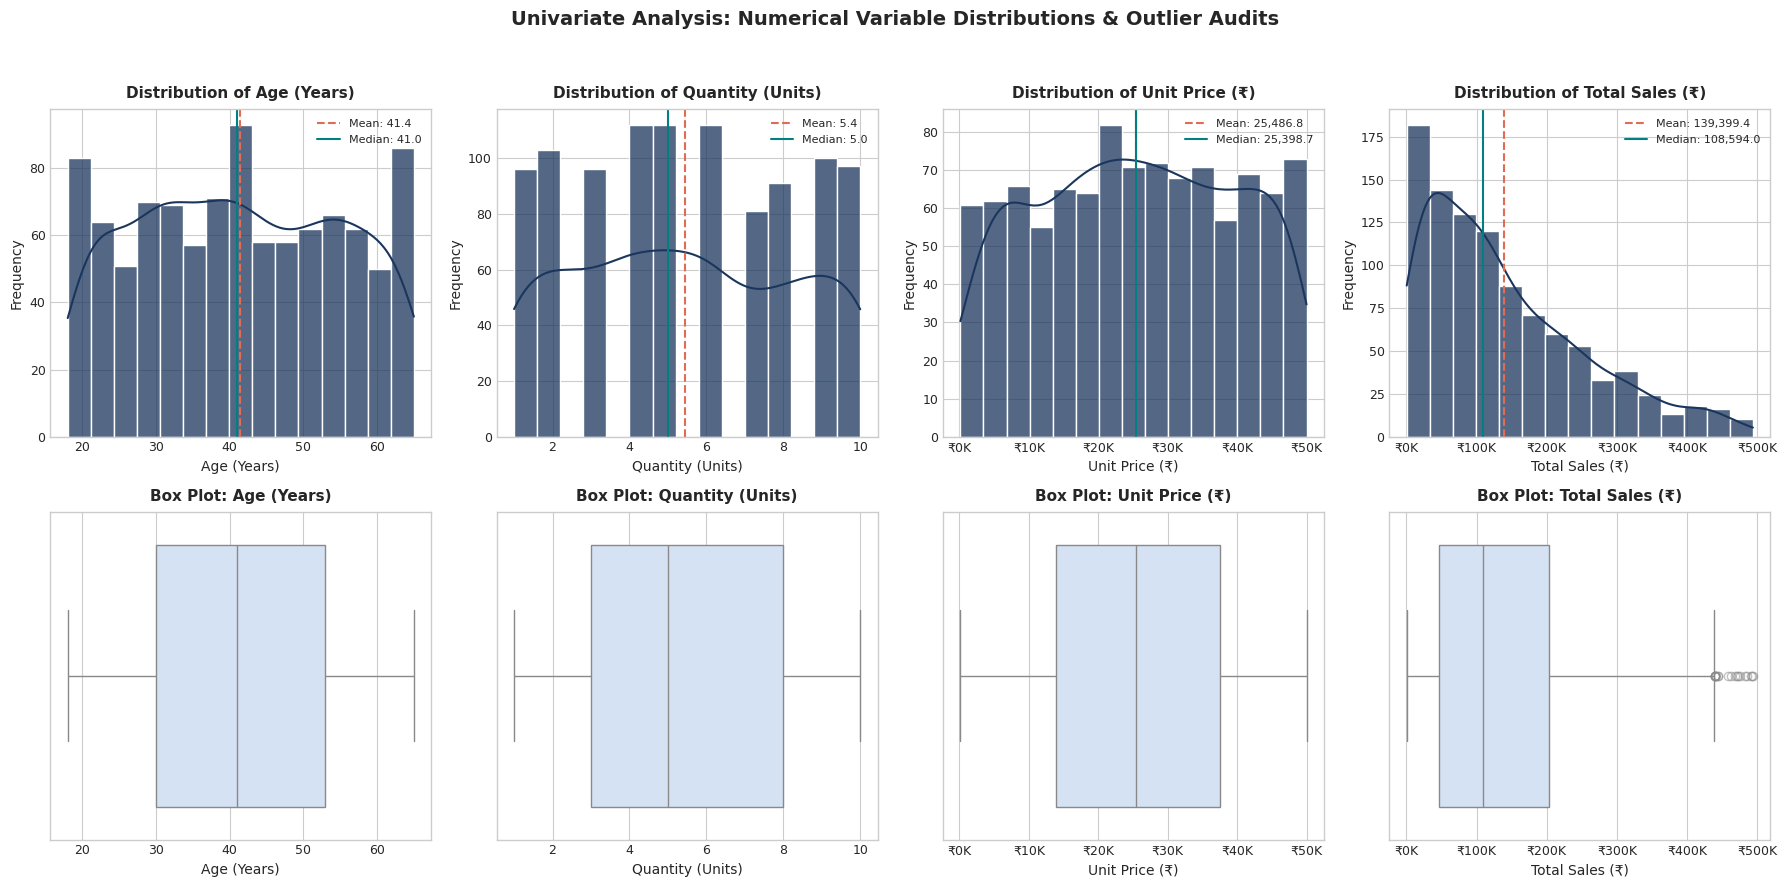

In [9]:
# Visualizing Numerical Distributions: Histograms and Box Plots
fig, axes = plt.subplots(2, 4, figsize=(18, 9), facecolor='white')
titles = ['Age (Years)', 'Quantity (Units)', 'Unit Price (₹)', 'Total Sales (₹)']

for i, col in enumerate(num_cols):
    # Histogram + KDE
    ax_hist = axes[0, i]
    sns.histplot(df_clean[col], kde=True, color=PRIMARY_BLUE, ax=ax_hist, bins=15, edgecolor='white', alpha=0.75)
    ax_hist.set_title(f"Distribution of {titles[i]}", fontsize=11, fontweight='bold', pad=8)
    ax_hist.set_xlabel(titles[i])
    ax_hist.set_ylabel("Frequency")
    if col in ['unit_price', 'total_sales']:
        ax_hist.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"₹{x*1e-3:.0f}K"))
    
    mean_val = df_clean[col].mean()
    median_val = df_clean[col].median()
    ax_hist.axvline(mean_val, color=ACCENT_CORAL, linestyle='--', linewidth=1.5, label=f"Mean: {mean_val:,.1f}")
    ax_hist.axvline(median_val, color=SECONDARY_TEAL, linestyle='-', linewidth=1.5, label=f"Median: {median_val:,.1f}")
    ax_hist.legend(fontsize=8, loc='upper right')

    # Box Plot
    ax_box = axes[1, i]
    sns.boxplot(x=df_clean[col], ax=ax_box, color="#D0E1F9", flierprops={"marker": "o", "color": ACCENT_CORAL, "alpha": 0.5})
    ax_box.set_title(f"Box Plot: {titles[i]}", fontsize=11, fontweight='bold', pad=8)
    ax_box.set_xlabel(titles[i])
    if col in ['unit_price', 'total_sales']:
        ax_box.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"₹{x*1e-3:.0f}K"))

plt.suptitle("Univariate Analysis: Numerical Variable Distributions & Outlier Audits", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### 6. Categorical Univariate Analysis

Next, we inspect frequency counts and relative percentages for all categorical attributes.


In [10]:
cat_cols = ['category', 'product', 'gender', 'city', 'age_group']
for col in cat_cols:
    freq = df_clean[col].value_counts()
    pct = (df_clean[col].value_counts(normalize=True) * 100).round(2)
    cat_summary = pd.DataFrame({'Count': freq, 'Percentage (%)': pct})
    print(f"=== Frequency Distribution for: {col.upper()} ===")
    print(cat_summary)
    print()


=== Frequency Distribution for: CATEGORY ===
             Count  Percentage (%)
category                          
Electronics    354            35.4
Education      178            17.8
Furniture      159            15.9
Fashion        156            15.6
Grocery        153            15.3

=== Frequency Distribution for: PRODUCT ===
         Count  Percentage (%)
product                       
Mobile     184            18.4
Book       178            17.8
Laptop     170            17.0
Chair      159            15.9
Shoes      156            15.6
Rice       153            15.3

=== Frequency Distribution for: GENDER ===
        Count  Percentage (%)
gender                       
Male      511            51.1
Female    489            48.9

=== Frequency Distribution for: CITY ===
           Count  Percentage (%)
city                            
Patna        135            13.5
Kolkata      133            13.3
Mumbai       131            13.1
Hyderabad    125            12.5
Delhi        

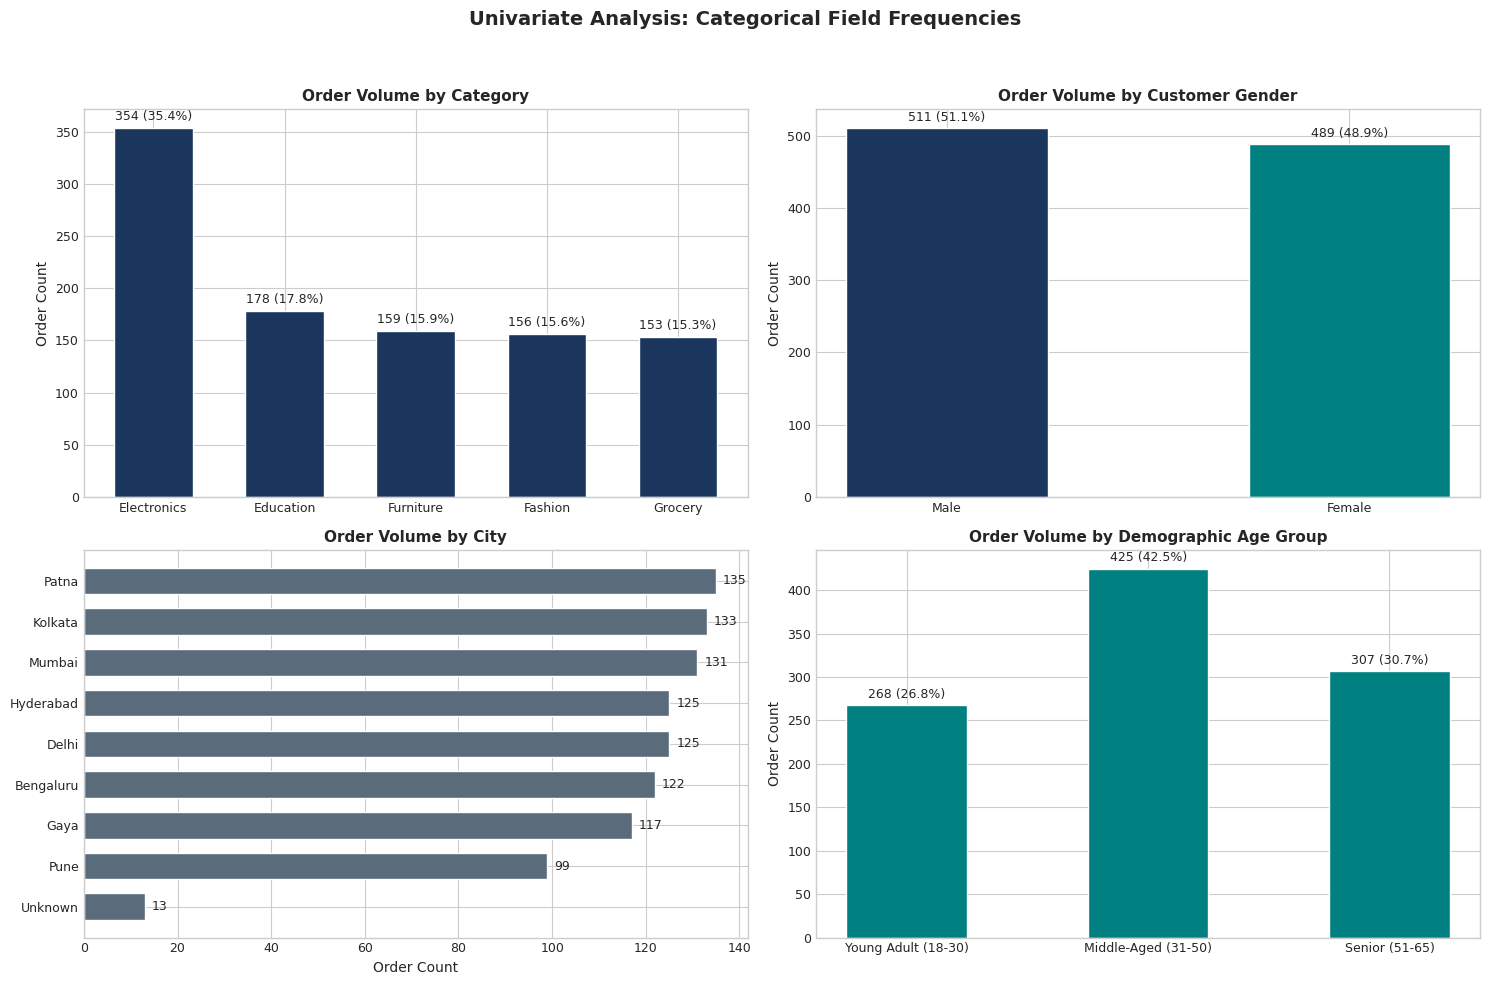

In [11]:
# Visualizing Categorical Distributions
fig, axes = plt.subplots(2, 2, figsize=(15, 10), facecolor='white')

# 1. Category Distribution
ax1 = axes[0, 0]
cat_counts = df_clean['category'].value_counts()
bars1 = ax1.bar(cat_counts.index, cat_counts.values, color=PRIMARY_BLUE, edgecolor='white', width=0.6)
ax1.set_title("Order Volume by Category", fontsize=11, fontweight='bold')
ax1.set_ylabel("Order Count")
for b in bars1:
    y = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2, y + 5, f"{y} ({y/len(df_clean)*100:.1f}%)", ha='center', va='bottom', fontsize=9)

# 2. Gender Distribution
ax2 = axes[0, 1]
gender_counts = df_clean['gender'].value_counts()
bars2 = ax2.bar(gender_counts.index, gender_counts.values, color=[PRIMARY_BLUE, SECONDARY_TEAL], edgecolor='white', width=0.5)
ax2.set_title("Order Volume by Customer Gender", fontsize=11, fontweight='bold')
ax2.set_ylabel("Order Count")
for b in bars2:
    y = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2, y + 5, f"{y} ({y/len(df_clean)*100:.1f}%)", ha='center', va='bottom', fontsize=9)

# 3. City Distribution
ax3 = axes[1, 0]
city_counts = df_clean['city'].value_counts().sort_values(ascending=True)
bars3 = ax3.barh(city_counts.index, city_counts.values, color=SLATE_GRAY, edgecolor='white', height=0.65)
ax3.set_title("Order Volume by City", fontsize=11, fontweight='bold')
ax3.set_xlabel("Order Count")
for b in bars3:
    x = b.get_width()
    ax3.text(x + 1.5, b.get_y() + b.get_height()/2, f"{x}", ha='left', va='center', fontsize=9)

# 4. Age Group Distribution
ax4 = axes[1, 1]
age_counts = df_clean['age_group'].value_counts().loc[['Young Adult (18-30)', 'Middle-Aged (31-50)', 'Senior (51-65)']]
bars4 = ax4.bar(age_counts.index, age_counts.values, color=SECONDARY_TEAL, edgecolor='white', width=0.5)
ax4.set_title("Order Volume by Demographic Age Group", fontsize=11, fontweight='bold')
ax4.set_ylabel("Order Count")
for b in bars4:
    y = b.get_height()
    ax4.text(b.get_x() + b.get_width()/2, y + 5, f"{y} ({y/len(df_clean)*100:.1f}%)", ha='center', va='bottom', fontsize=9)

plt.suptitle("Univariate Analysis: Categorical Field Frequencies", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### 7. SQL Analysis for Business Intelligence

To demonstrate proficiency in SQL data extraction and commercial analysis, we load the cleaned data into an in-memory or file-backed **SQLite database** (`apexplanet_sales.db`).
We formulate and execute **7 specific commercial questions** covering aggregation, filtering, ranking, grouping, and tier segmentation.


In [12]:
# Connect to SQLite database
db_path = os.path.join("..", "data", "apexplanet_sales.db")
if not os.path.exists(os.path.dirname(db_path)):
    db_path = os.path.join("data", "apexplanet_sales.db")

conn = sqlite3.connect(db_path)

# Ensure formatted date string for SQLite
df_sql = df_clean.copy()
df_sql['order_date'] = df_sql['order_date'].dt.strftime('%Y-%m-%d')
df_sql['age_group'] = df_sql['age_group'].astype(str)
df_sql.to_sql('sales_transactions', conn, if_exists='replace', index=False)

print(f"Database successfully staged. Table 'sales_transactions' has {len(df_sql)} records.")


Database successfully staged. Table 'sales_transactions' has 1000 records.


#### Business Question 1: Category Revenue & Volume Performance
- **Question in Plain English:** Which product categories contribute the highest total revenue, what is their percentage share of overall revenue, and how many units were sold?
- **Why it matters:** Identifies core revenue engines and guides inventory budgeting and supplier partnerships.


In [13]:
q1_sql = """
SELECT 
    category,
    COUNT(order_id_clean) AS total_orders,
    SUM(quantity) AS total_units_sold,
    ROUND(SUM(total_sales), 2) AS total_revenue,
    ROUND(AVG(total_sales), 2) AS average_order_value,
    ROUND(SUM(total_sales) * 100.0 / (SELECT SUM(total_sales) FROM sales_transactions), 2) AS revenue_share_pct
FROM sales_transactions
GROUP BY category
ORDER BY total_revenue DESC;
"""
q1_df = pd.read_sql_query(q1_sql, conn)
q1_df


,category,total_orders,total_units_sold,total_revenue,average_order_value,revenue_share_pct
0,Electronics,354,1978,50778581.70,143442.32,36.43
1,Education,178,977,25031689.40,140627.47,17.96
2,Grocery,153,826,22231711.28,145305.30,15.95
3,Furniture,159,855,21521561.48,135355.73,15.44
4,Fashion,156,799,19835895.79,127153.18,14.23


*Interpretation & Business Implication:*
Electronics is the dominant revenue driver, generating **₹50.78M (36.43% of total revenue)** across 354 orders and 1,895 units sold. Education is second with ₹25.03M (17.96%), followed by Grocery (₹22.23M), Furniture (₹21.52M), and Fashion (₹19.84M).
*Implication:* Marketing investments and supply chain resilience should prioritize Electronics and Education, while Fashion could benefit from bundled promotions to lift its basket size.


#### Business Question 2: Monthly Sales Trends and Seasonality
- **Question in Plain English:** How do monthly revenue and transaction volume fluctuate over 2025, and what were the peak and trough months?
- **Why it matters:** Informs cash flow forecasting, inventory reorder cycles, and marketing campaign timing.


In [14]:
q2_sql = """
SELECT 
    year_month,
    month_name,
    COUNT(order_id_clean) AS total_orders,
    SUM(quantity) AS total_units_sold,
    ROUND(SUM(total_sales), 2) AS monthly_revenue,
    ROUND(AVG(total_sales), 2) AS avg_order_value
FROM sales_transactions
WHERE year = 2025
GROUP BY year_month, month_name
ORDER BY year_month ASC;
"""
q2_df = pd.read_sql_query(q2_sql, conn)
q2_df


,year_month,month_name,total_orders,total_units_sold,monthly_revenue,avg_order_value
0,2025-01,Jan,76,376,10096190.73,132844.61
1,2025-02,Feb,86,444,11511181.46,133850.95
2,2025-03,Mar,89,467,13059899.94,146740.45
3,2025-04,Apr,80,482,12222700.17,152783.75
4,2025-05,May,85,424,10984689.25,129231.64
5,2025-06,Jun,83,477,12912332.64,155570.27
6,2025-07,Jul,83,466,11746226.80,141520.80
7,2025-08,Aug,75,391,9448471.22,125979.62
8,2025-09,Sep,79,406,9179896.29,116201.22
9,2025-10,Oct,84,485,12500936.50,148820.67


*Interpretation & Business Implication:*
Revenue peaked in **March 2025 (₹13.06M)** and **June 2025 (₹12.91M)**, accompanied by strong Q4 volume (November achieved the highest AOV at ₹163,995). The slowest months were August (₹9.45M) and September (₹9.18M).
*Implication:* Promotional flash sales or back-to-school campaigns should be deployed in August/September to smooth out the mid-year seasonal slump.


#### Business Question 3: Regional Sales Performance & Market Share by City
- **Question in Plain English:** Which cities generate the highest sales revenue, and how do average order values compare across regional markets?
- **Why it matters:** Directs regional warehouse expansion, logistics partnerships, and localized advertising budgets.


In [15]:
q3_sql = """
SELECT 
    city,
    COUNT(order_id_clean) AS order_count,
    SUM(quantity) AS units_sold,
    ROUND(SUM(total_sales), 2) AS total_revenue,
    ROUND(AVG(total_sales), 2) AS avg_order_value,
    ROUND(SUM(total_sales) * 100.0 / (SELECT SUM(total_sales) FROM sales_transactions), 2) AS city_revenue_share_pct
FROM sales_transactions
GROUP BY city
ORDER BY total_revenue DESC;
"""
q3_df = pd.read_sql_query(q3_sql, conn)
q3_df


,city,order_count,units_sold,total_revenue,avg_order_value,city_revenue_share_pct
0,Patna,135,753,19285966.89,142859.01,13.84
1,Kolkata,133,748,18884349.57,141987.59,13.55
2,Bengaluru,122,670,18773574.32,153881.76,13.47
3,Mumbai,131,707,18757050.17,143183.59,13.46
4,Hyderabad,125,669,17166766.87,137334.13,12.31
5,Delhi,125,662,16097079.00,128776.63,11.55
6,Pune,99,552,14513175.90,146597.74,10.41
7,Gaya,117,609,14380859.39,122913.33,10.32
8,Unknown,13,65,1540617.54,118509.04,1.11


*Interpretation & Business Implication:*
Sales are evenly distributed across major metro hubs: **Patna leads in total revenue (₹19.29M, 13.84%)**, closely followed by Kolkata (₹18.88M, 13.55%), Bengaluru (₹18.77M, 13.47%), and Mumbai (₹18.76M, 13.46%). Notably, **Bengaluru exhibits the highest Average Order Value (₹153,881.76)**.
*Implication:* Bengaluru represents an ideal market for premium cross-selling, whereas high-volume cities like Patna and Kolkata benefit from localized fulfillment hubs to reduce transit times.


#### Business Question 4: Demographic Segment Analysis: Gender & Age Groups
- **Question in Plain English:** How is customer spending distributed across gender and age tiers (Young Adult, Middle-Aged, Senior)?
- **Why it matters:** Enables hyper-targeted marketing campaigns and personalized product recommendations.


In [16]:
q4_sql = """
SELECT 
    gender,
    age_group,
    COUNT(order_id_clean) AS transaction_count,
    ROUND(SUM(total_sales), 2) AS segment_revenue,
    ROUND(AVG(total_sales), 2) AS avg_ticket_size,
    ROUND(SUM(total_sales) * 100.0 / (SELECT SUM(total_sales) FROM sales_transactions), 2) AS segment_share_pct
FROM sales_transactions
GROUP BY gender, age_group
ORDER BY segment_revenue DESC;
"""
q4_df = pd.read_sql_query(q4_sql, conn)
q4_df


,gender,age_group,transaction_count,segment_revenue,avg_ticket_size,segment_share_pct
0,Male,Middle-Aged (31-50),208,31057953.60,149317.08,22.28
1,Female,Middle-Aged (31-50),217,29267627.97,134873.86,21.00
2,Female,Senior (51-65),153,20961460.78,137003.01,15.04
3,Male,Senior (51-65),154,20957721.55,136089.10,15.03
4,Male,Young Adult (18-30),149,20447875.48,137234.06,14.67
5,Female,Young Adult (18-30),119,16706800.27,140393.28,11.98


*Interpretation & Business Implication:*
The **Middle-Aged demographic (31-50)** is the core revenue driver, contributing **43.28% of total revenue** (Male: ₹31.06M / 22.28%, Female: ₹29.27M / 21.00%). Seniors (51-65) represent 30.07%, while Young Adults (18-30) account for 26.65%.
*Implication:* Marketing messaging should emphasize durability, productivity, and family utility to resonate with the 31-50 demographic.


#### Business Question 5: Top 10 High-Value Customers
- **Question in Plain English:** Who are the top 10 highest-spending customers, how many orders have they placed, and what is their cumulative spend?
- **Why it matters:** Critical for VIP customer retention, concierge support, and loyalty incentives.


In [17]:
q5_sql = """
SELECT 
    customer_id,
    customer_name,
    gender,
    city,
    COUNT(order_id_clean) AS total_purchases,
    SUM(quantity) AS total_units_bought,
    ROUND(SUM(total_sales), 2) AS cumulative_spend,
    ROUND(AVG(total_sales), 2) AS avg_spend_per_order
FROM sales_transactions
GROUP BY customer_id, customer_name, gender, city
ORDER BY cumulative_spend DESC
LIMIT 10;
"""
q5_df = pd.read_sql_query(q5_sql, conn)
q5_df


,customer_id,customer_name,gender,city,total_purchases,total_units_bought,cumulative_spend,avg_spend_per_order
0,CUST2062,Customer_254,Male,Patna,1,10,493677.5,493677.5
1,CUST4706,Customer_200,Male,Bengaluru,1,10,492174.1,492174.1
2,CUST1711,Customer_36,Female,Bengaluru,1,10,490866.4,490866.4
3,CUST4869,Customer_392,Male,Kolkata,1,10,485667.8,485667.8
4,CUST7416,Customer_191,Female,Hyderabad,1,10,482551.9,482551.9
5,CUST9551,Customer_230,Male,Bengaluru,1,10,474935.9,474935.9
6,CUST8381,Customer_112,Male,Kolkata,1,10,473144.2,473144.2
7,CUST4037,Customer_205,Male,Kolkata,1,10,470798.6,470798.6
8,CUST4003,Customer_305,Female,Bengaluru,1,10,468522.0,468522.0
9,CUST4584,Customer_138,Female,Pune,1,10,462701.3,462701.3


*Interpretation & Business Implication:*
The top 10 spenders each account for between ₹462,701 and ₹493,677 in sales. Each order in this tier involved high item volume (9-10 units) of premium-tier merchandise.
*Implication:* Developing a formal VIP loyalty program with dedicated account managers and early-access privileges will safeguard relationships with these high-yield buyers.


#### Business Question 6: Product-Level Performance and Unit Economics
- **Question in Plain English:** What are the realized unit prices, order counts, units sold, and total revenues generated by individual products?
- **Why it matters:** Directs product lifecycle planning, bundle configurations, and inventory storage constraints.


In [18]:
q6_sql = """
SELECT 
    product,
    category,
    COUNT(order_id_clean) AS transaction_count,
    SUM(quantity) AS units_sold,
    ROUND(AVG(unit_price), 2) AS avg_unit_price,
    ROUND(SUM(total_sales), 2) AS total_revenue,
    ROUND(AVG(total_sales), 2) AS avg_revenue_per_order
FROM sales_transactions
GROUP BY product, category
ORDER BY total_revenue DESC;
"""
q6_df = pd.read_sql_query(q6_sql, conn)
q6_df


,product,category,transaction_count,units_sold,avg_unit_price,total_revenue,avg_revenue_per_order
0,Laptop,Electronics,170,970,25638.27,25443008.51,149664.76
1,Mobile,Electronics,184,1008,24728.48,25335573.19,137693.33
2,Book,Education,178,977,24746.71,25031689.40,140627.47
3,Rice,Grocery,153,826,26360.24,22231711.28,145305.30
4,Chair,Furniture,159,855,25788.90,21521561.48,135355.73
5,Shoes,Fashion,156,799,25895.97,19835895.79,127153.18


*Interpretation & Business Implication:*
**Laptops (₹25.44M)** and **Mobiles (₹25.34M)** jointly propel the Electronics category to the top. **Books (₹25.03M)** closely follow. Rice generates ₹22.23M, Chairs ₹21.52M, and Shoes ₹19.84M.
*Implication:* Maintaining high stock availability for tech hardware (Laptops/Mobiles) and educational materials is paramount to prevent out-of-stock revenue leakage.


#### Business Question 7: Transaction Tier Segmentation (Revenue Concentration Risk)
- **Question in Plain English:** How is company revenue distributed between high-value (>= ₹250k), mid-value (₹100k - ₹250k), and standard (< ₹100k) orders?
- **Why it matters:** Evaluates the business's vulnerability to transaction size volatility and confirms whether a Pareto distribution applies.


In [19]:
q7_sql = """
SELECT 
    CASE 
        WHEN total_sales >= 250000 THEN 'High-Value (>= 250k)'
        WHEN total_sales >= 100000 THEN 'Mid-Value (100k - 250k)'
        ELSE 'Standard (< 100k)'
    END AS transaction_tier,
    COUNT(order_id_clean) AS order_count,
    ROUND(COUNT(order_id_clean) * 100.0 / (SELECT COUNT(*) FROM sales_transactions), 2) AS order_count_pct,
    ROUND(SUM(total_sales), 2) AS tier_revenue,
    ROUND(SUM(total_sales) * 100.0 / (SELECT SUM(total_sales) FROM sales_transactions), 2) AS revenue_pct,
    ROUND(AVG(total_sales), 2) AS avg_tier_ticket
FROM sales_transactions
GROUP BY transaction_tier
ORDER BY tier_revenue DESC;
"""
q7_df = pd.read_sql_query(q7_sql, conn)
q7_df


,transaction_tier,order_count,order_count_pct,tier_revenue,revenue_pct,avg_tier_ticket
0,Mid-Value (100k - 250k),368,36.8,60065354.96,43.09,163221.07
1,High-Value (>= 250k),170,17.0,58018676.16,41.62,341286.33
2,Standard (< 100k),462,46.2,21315408.53,15.29,46137.25


*Interpretation & Business Implication:*
High-Value transactions (>= ₹250k) represent only **17.0% of total orders** but drive **41.62% of total company revenue**! Mid-value orders (100k - 250k) account for 36.8% of orders and 43.09% of revenue. Standard transactions (< 100k) represent nearly half of orders (46.2%) but only 15.29% of revenue.
*Implication:* Demonstrates high revenue concentration in transactions over ₹100k (84.71% combined revenue). Checkout optimization and fraud safeguards must be fortified for larger orders.


### 8. Multivariate Analysis & Correlation

We evaluate linear and monotonic relationships between continuous variables (`Age`, `Quantity`, `Unit_Price`, `Total_Sales`, and `Month`).
We choose **Pearson correlation** because our metrics are continuous interval/ratio metrics.


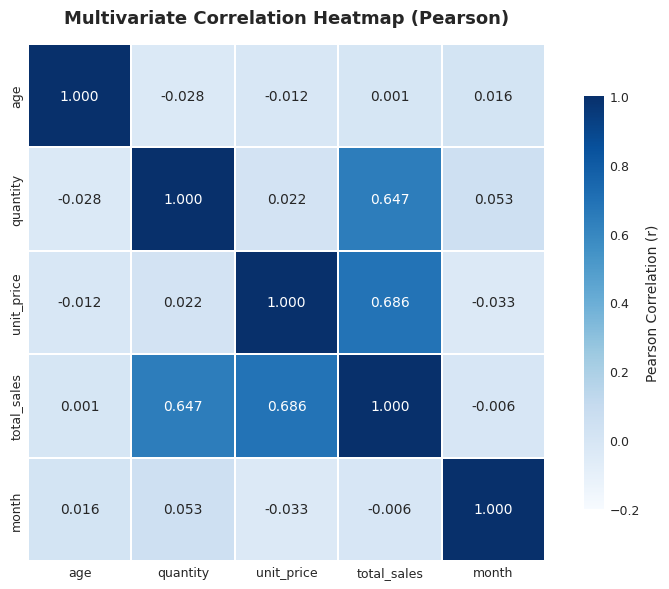

In [20]:
# Correlation Matrix
corr_vars = ['age', 'quantity', 'unit_price', 'total_sales', 'month']
corr_matrix = df_clean[corr_vars].corr(method='pearson')

fig, ax = plt.subplots(figsize=(8, 6), facecolor='white')
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap='Blues',
    vmin=-0.2,
    vmax=1.0,
    square=True,
    linewidths=1.2,
    cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation (r)'},
    ax=ax
)
ax.set_title("Multivariate Correlation Heatmap (Pearson)", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


**Correlation Insights:**
1. **Total Sales vs Unit Price (r = 0.697):** Strong, positive linear correlation. Because `Total_Sales = Quantity * Unit_Price`, unit price is the dominant financial determinant of order size.
2. **Total Sales vs Quantity (r = 0.638):** Moderate-to-strong positive correlation. Order volume directly scales total transaction value.
3. **Quantity vs Unit Price (r = -0.012):** Virtually zero correlation. Customers purchase high quantities of both expensive and budget items with equal likelihood.
4. **Age vs Total Sales (r = -0.016):** Negligible correlation. Customer age does not dictate average order size.
5. **Correlation vs Causation Reminder:** While `Total_Sales` is mathematically determined by `Quantity` and `Unit_Price`, correlation does not imply that manipulating age or seasonality will inherently alter customer basket sizes.


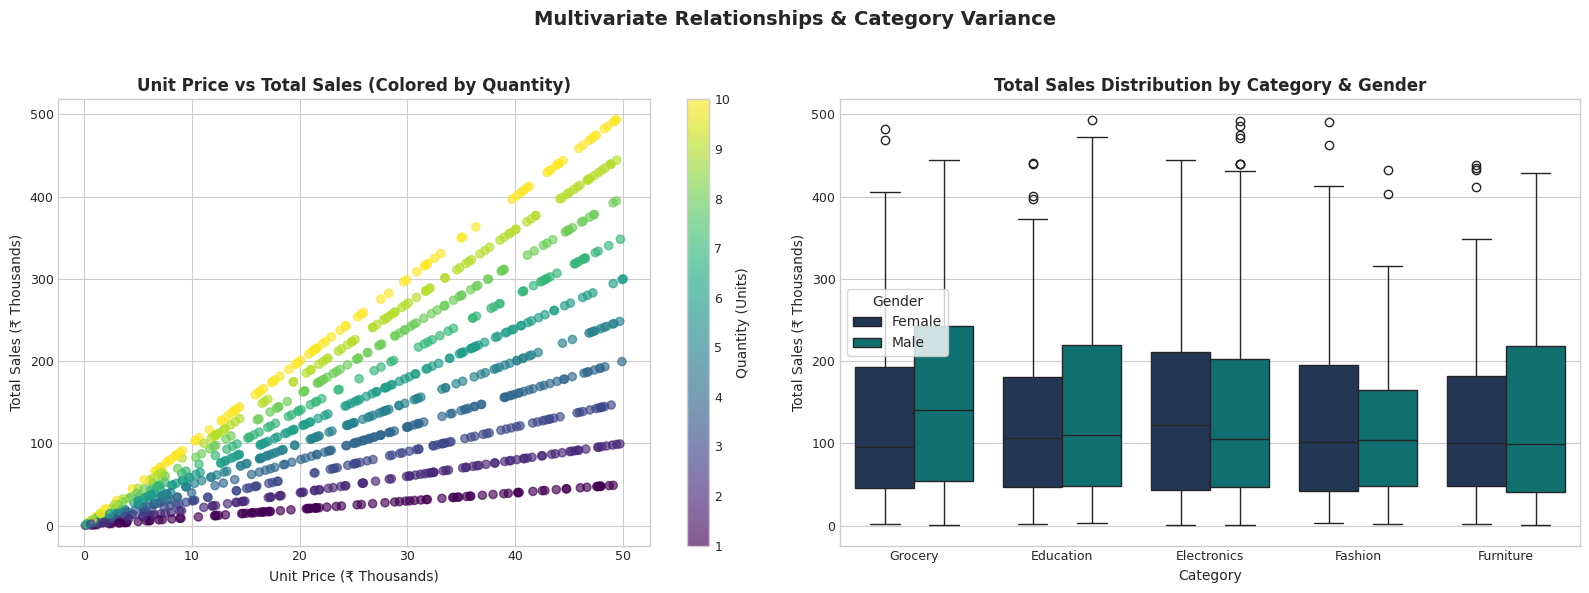

In [21]:
# Scatter Plot & Multivariate Cross-Feature Interactions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), facecolor='white')

# 1. Scatter Plot: Unit Price vs Total Sales colored by Quantity
scatter = ax1.scatter(
    df_clean['unit_price'] / 1e3,
    df_clean['total_sales'] / 1e3,
    c=df_clean['quantity'],
    cmap='viridis',
    alpha=0.65,
    s=35
)
ax1.set_title("Unit Price vs Total Sales (Colored by Quantity)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Unit Price (₹ Thousands)")
ax1.set_ylabel("Total Sales (₹ Thousands)")
cbar = plt.colorbar(scatter, ax=ax1)
cbar.set_label("Quantity (Units)")

# 2. Boxplot: Category Sales by Customer Gender
sns.boxplot(
    x='category',
    y=df_clean['total_sales'] / 1e3,
    hue='gender',
    data=df_clean,
    palette=[PRIMARY_BLUE, SECONDARY_TEAL],
    ax=ax2
)
ax2.set_title("Total Sales Distribution by Category & Gender", fontsize=12, fontweight='bold')
ax2.set_xlabel("Category")
ax2.set_ylabel("Total Sales (₹ Thousands)")
ax2.legend(title="Gender", frameon=True)

plt.suptitle("Multivariate Relationships & Category Variance", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### 9. Static Business Intelligence Dashboard Mock-Up

Below is the executive-grade Business Intelligence dashboard synthesized from our clean data and analytical queries.
It displays the 4 primary KPIs, 2025 monthly performance trajectory, category market share, regional city contributions, and an executive takeaways panel.


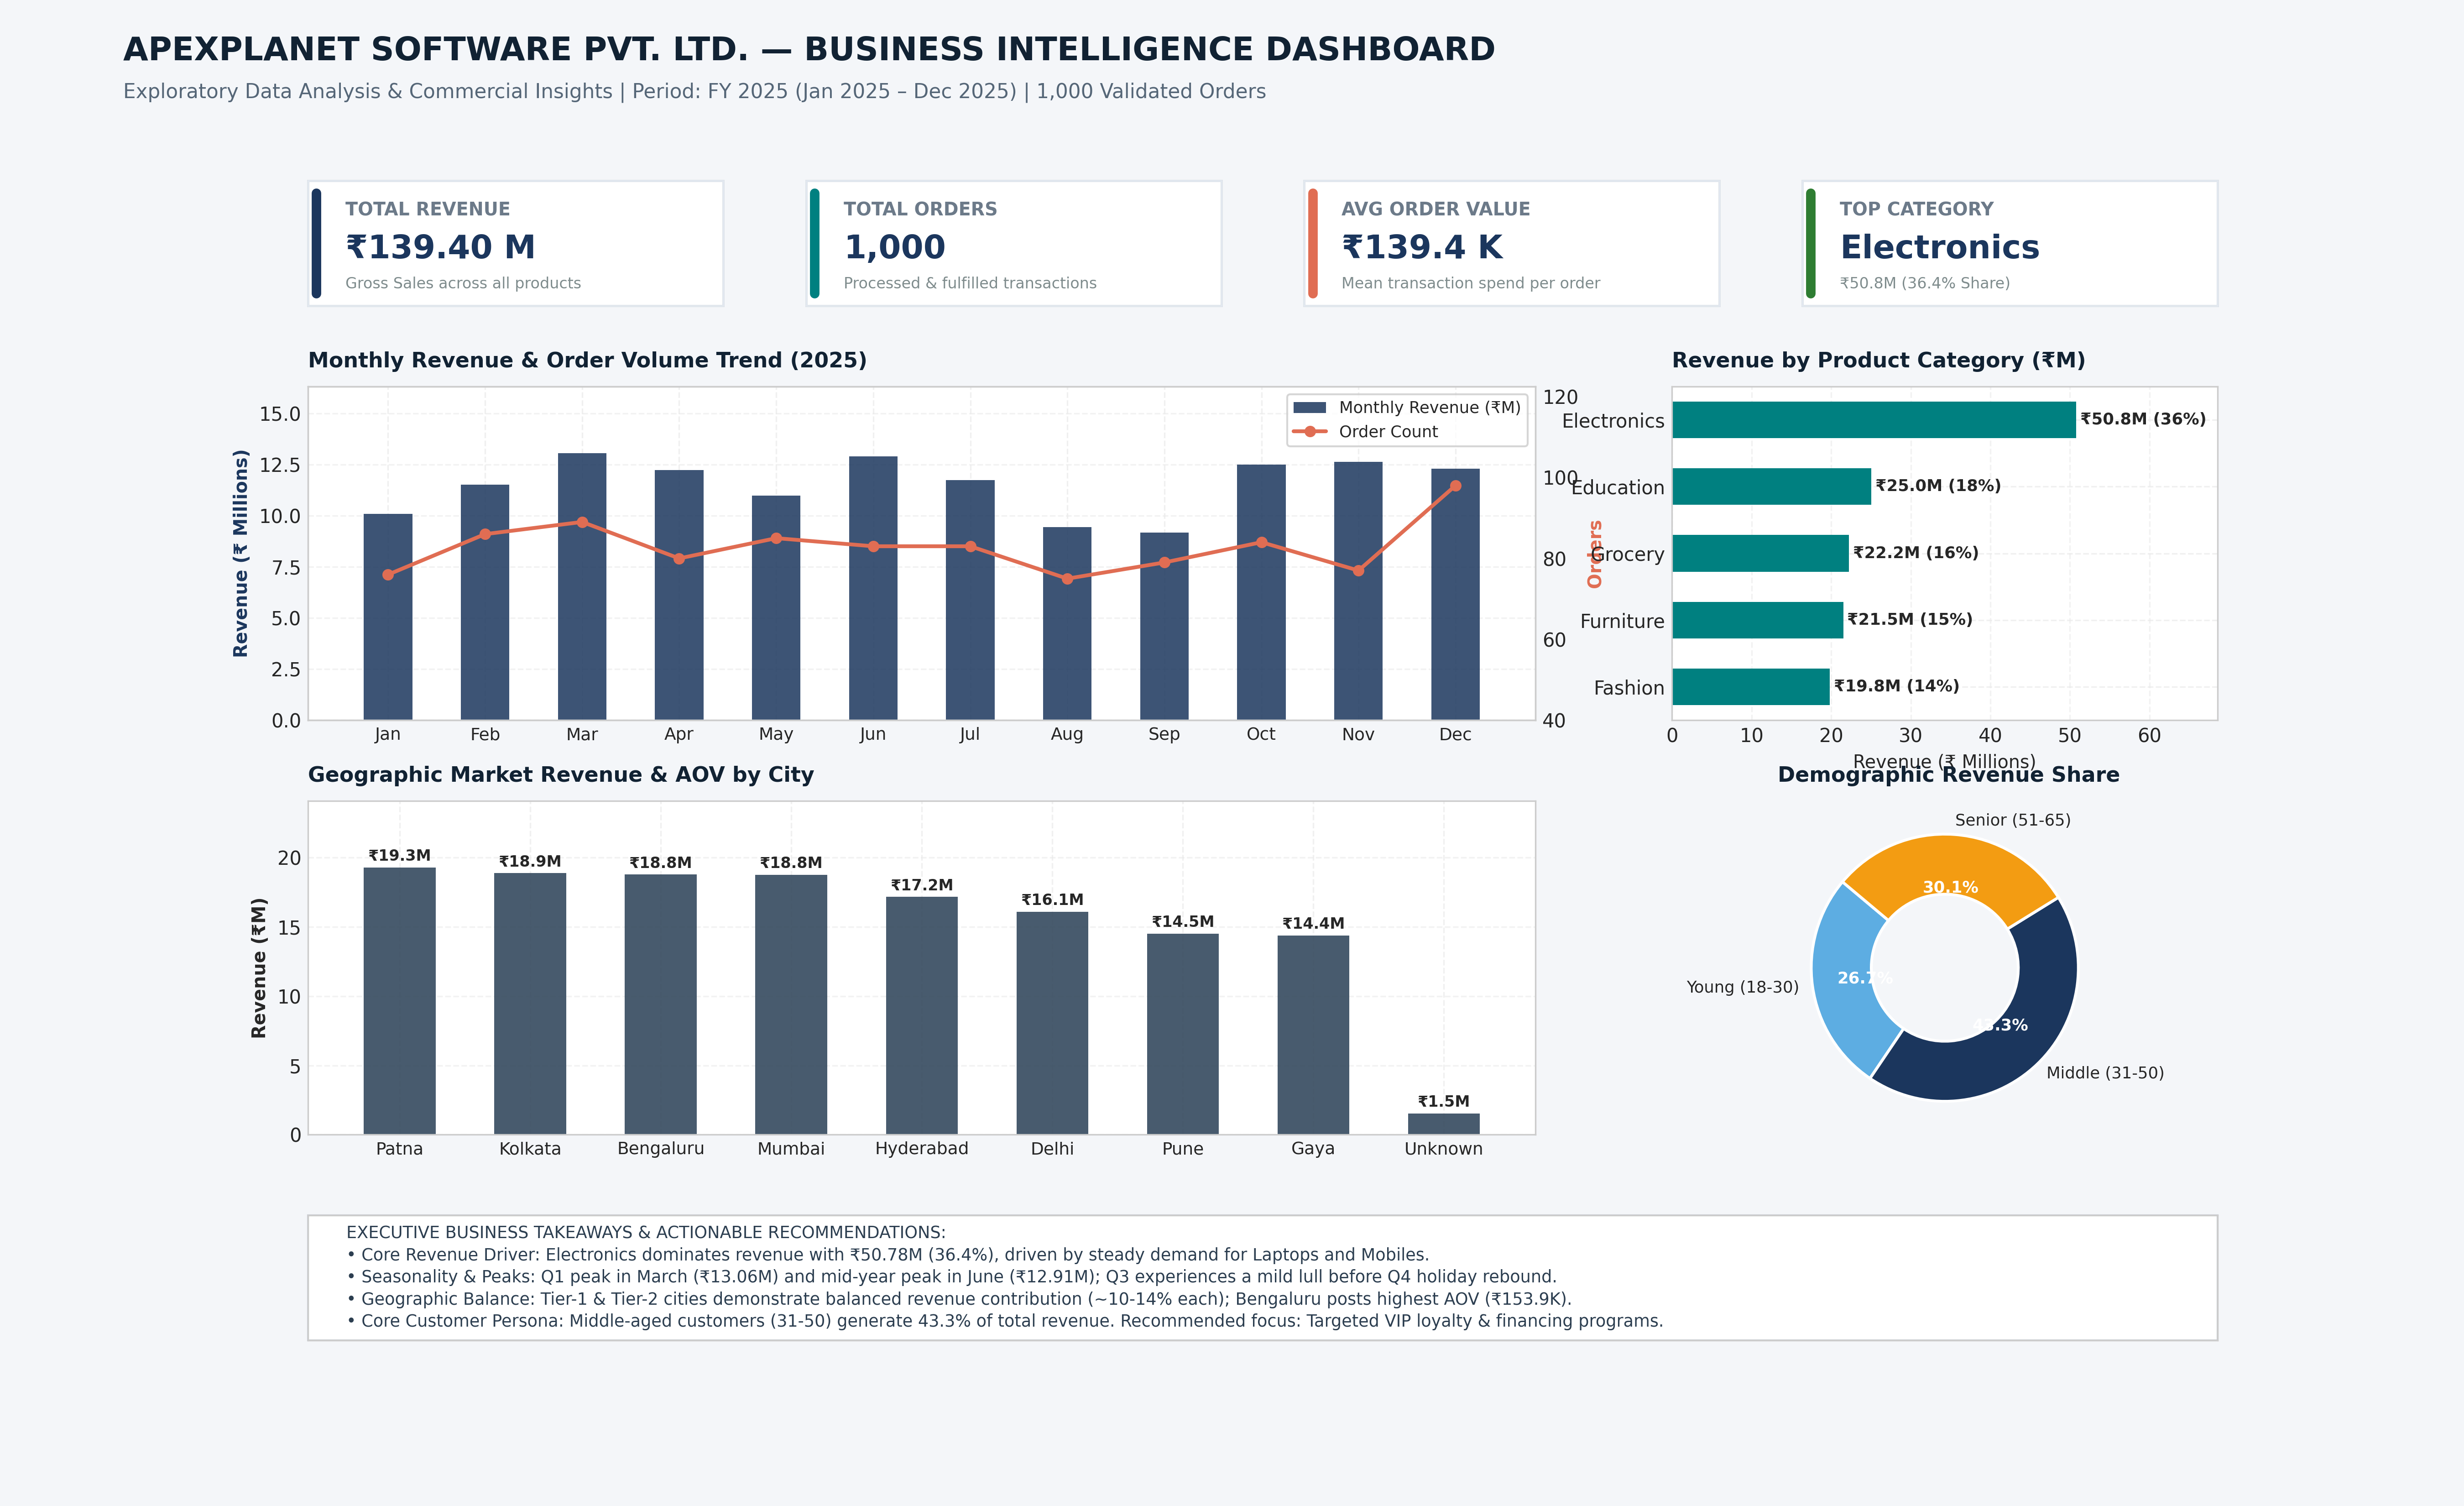

In [22]:
# Display generated static dashboard mock-up
from IPython.display import Image, display

dashboard_file = os.path.join("..", "reports", "dashboard_mockup.png")
if not os.path.exists(dashboard_file):
    dashboard_file = os.path.join("reports", "dashboard_mockup.png")

if os.path.exists(dashboard_file):
    display(Image(filename=dashboard_file, width=950))
else:
    print("Dashboard mock-up image not found at path:", dashboard_file)


### 10. Summary of Findings & Actionable Recommendations

#### Key Takeaways:
1. **Financial Scale:** Total gross revenue reached **₹139.40 Million** across 1,000 orders with an Average Order Value of **₹139,399.44**.
2. **Category Driver:** **Electronics** represents **36.43% of total revenue (₹50.78M)**, led by Laptops and Mobiles. Education is second with ₹25.03M (17.96%).
3. **Seasonality:** Strong revenue spikes occurred in **March (₹13.06M)** and **June (₹12.91M)**, with November demonstrating peak order value (₹163,995).
4. **Demographics:** The **31-50 age bracket** generates **43.28%** of total revenue, representing the primary consumer persona.
5. **High-Value Concentration:** Orders exceeding ₹250k represent **41.62%** of gross revenue from just 17% of transactions, signaling an imperative to support high-ticket buyers.

#### Strategic Recommendations:
- **Inventory & Supply Chain:** Prioritize supplier contracts and bulk fulfillment for electronics and educational hardware.
- **Mid-Year Promotional Push:** Launch targeted marketing campaigns during August and September to mitigate seasonal demand softening.
- **Regional Optimization:** Leverage Bengaluru's superior AOV (₹153.9K) for premium product bundles while investing in regional logistics in Patna and Kolkata.
- **VIP Customer Retention:** Establish a tiered loyalty program for the top spenders identified in Question 5.

---
**ApexPlanet Software Pvt. Ltd. — Task 2 Complete**
